# CS406 – Đề tài : Fashion Image Retrieval
**Bài toán.** Input: ảnh sản phẩm thời trang (query) → Output: Top-K ảnh giống nhất trong gallery. Đúng = cùng `articleType`
(tiêu chí chặt hơn: cùng `articleType` **và** `baseColour`).

**handcrafted (Hist+LBP, có/không tiền xử lý, theo vùng),
ResNet50/VGG16 pretrained, ResNet50 **fine-tune triplet**, và các phương pháp **kết hợp**.

In [1]:
import os, glob, random, time, warnings, subprocess, sys
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from skimage.feature import local_binary_pattern
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)
IMG = int(os.environ.get('IMG', 128))
N_VAL, N_TEST = int(os.environ.get('N_VAL', 500)), int(os.environ.get('N_TEST', 1000))
MIN_PER_CLASS = int(os.environ.get('MIN_PER_CLASS', 50))
UNSEEN_K = int(os.environ.get('UNSEEN_K', 8))        # số lớp giữ lại, không dùng khi train
TRAIN_FRAC = 0.5                                      # tỉ lệ ảnh (của lớp seen) dùng để train
ITERS = int(os.environ.get('ITERS', 1500)); EVAL_EVERY = int(os.environ.get('EVAL_EVERY', 500))
P_CLS, K_IMG, MARGIN, EMB = 16, 8, 0.3, 256           # PK-sampling: 16 lớp x 8 ảnh = batch 128
DUP_RMSE = float(os.environ.get('DUP_RMSE', 6.0))        # ngưỡng gần trùng: RMSE (mức xám 0-255) trên ảnh 16x16 màu
UNSEEN_Q_FRAC = 0.25                                   # tỉ lệ query lấy từ lớp unseen (để đủ mẫu đánh giá)
BG_METHOD = os.environ.get('BG_METHOD', 'flood')       # 'flood' (nền gần trắng nối với viền)
AUG_ROBUST = True                                      # augmentation nhiễu/mờ khi fine-tune
DATA_ROOT = os.environ.get('DATA_ROOT', '/kaggle/input')
OUT = os.environ.get('OUT_DIR', '/kaggle/working'); os.makedirs(OUT, exist_ok=True)

# 1. Dữ liệu và chia train / eval

In [2]:
def find_file(root, name):
    return [os.path.join(r, f) for r, _, fs in os.walk(root) for f in fs if f == name]

found = find_file(DATA_ROOT, 'styles.csv')
if not found:
    try:
        import kagglehub
        DATA_ROOT = kagglehub.dataset_download('paramaggarwal/fashion-product-images-small'); found = find_file(DATA_ROOT, 'styles.csv')
    except Exception as e:
        print('kagglehub lỗi:', e)
if not found:
    raise FileNotFoundError('Không thấy styles.csv. Add dataset "fashion-product-images-small" (paramaggarwal) vào notebook.')
IMAGES_DIR = os.path.join(os.path.dirname(found[0]), 'images')
df = pd.read_csv(found[0], on_bad_lines='skip')
df['path'] = df['id'].astype(str).map(lambda i: os.path.join(IMAGES_DIR, f'{i}.jpg'))
df = df[df['path'].map(os.path.exists)].dropna(subset=['articleType']).copy()
df['baseColour'] = df['baseColour'].fillna('unknown')
vc = df['articleType'].value_counts()
df = df[df['articleType'].isin(vc[vc >= MIN_PER_CLASS].index)].reset_index(drop=True)
print(f'{len(df)} ảnh, {df.articleType.nunique()} lớp')

atype = np.asarray(df['articleType'], dtype=object); colour = np.asarray(df['baseColour'], dtype=object)
lab = df['articleType'].astype('category').cat.codes.values.astype(np.int64)

43328 ảnh, 70 lớp


In [3]:
def resize_with_padding(img, size=IMG):
    h, w = img.shape[:2]; s = size / max(h, w)
    nw, nh = max(1, int(w * s)), max(1, int(h * s))
    canvas = np.full((size, size, 3), 255, np.uint8)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
    return canvas

def small_desc(img):
    """Ảnh 16x16 màu (768 giá trị) – dùng để dò ảnh gần trùng. (aHash 8x8 cũ trùng nhầm hàng loạt vì nền trắng.)"""
    return cv2.resize(img, (16, 16), interpolation=cv2.INTER_AREA).ravel()

def load_img(p):
    im = cv2.imread(p)
    if im is None: im = np.full((80, 60, 3), 255, np.uint8)
    pad = resize_with_padding(im)
    return pad, small_desc(pad)

from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
def pmap(fn, items, workers=8, desc=None):
    """map song song bằng thread (cv2 nhả GIL)"""
    with ThreadPoolExecutor(max_workers=workers) as ex:
        return list(tqdm(ex.map(fn, items), total=len(items), desc=desc))

cache_img = f'{OUT}/images_{IMG}_v2.npz'
if os.path.exists(cache_img) and len(np.load(cache_img)['desc']) == len(df):
    z = np.load(cache_img); X, DESC = z['x'], z['desc']; print('Đọc cache ảnh')
else:
    t0 = time.time(); res = pmap(load_img, df['path'], 16, 'nạp ảnh')
    X = np.stack([r[0] for r in res]); DESC = np.stack([r[1] for r in res]); del res
    np.savez(cache_img, x=X, desc=DESC); print(f'Đã nạp {X.shape} ({X.nbytes / 1e9:.1f} GB) trong {time.time() - t0:.0f}s')

nạp ảnh:   0%|          | 0/43328 [00:00<?, ?it/s]

Đã nạp (43328, 128, 128, 3) (2.1 GB) trong 257s


In [4]:
rng = np.random.RandomState(SEED)
vc = df['articleType'].value_counts()
cands = vc[(vc >= 100) & (vc <= 1500)].index.to_numpy()
unseen = rng.choice(cands, min(UNSEEN_K, len(cands)), replace=False)
is_unseen = df['articleType'].isin(unseen).values
print('Lớp UNSEEN:', list(unseen))

seen_idx = rng.permutation(np.where(~is_unseen)[0]); unseen_idx = rng.permutation(np.where(is_unseen)[0])
n_tr = int(TRAIN_FRAC * len(seen_idx))
train_idx, ev_seen = seen_idx[:n_tr], seen_idx[n_tr:]
nv_u, nt_u = int(N_VAL * UNSEEN_Q_FRAC), int(N_TEST * UNSEEN_Q_FRAC); nv_s, nt_s = N_VAL - nv_u, N_TEST - nt_u
val_idx = np.concatenate([ev_seen[:nv_s], unseen_idx[:nv_u]])
test_idx = np.concatenate([ev_seen[nv_s:nv_s + nt_s], unseen_idx[nv_u:nv_u + nt_u]])
rest = np.concatenate([ev_seen[nv_s + nt_s:], unseen_idx[nv_u + nt_u:]])

D32 = DESC.astype(np.float32)
def near_dup(targets, qs, thr=DUP_RMSE):
    """True với ảnh đích có RMSE <= thr so với ít nhất 1 query. Trả thêm khoảng cách gần nhất để hiệu chỉnh ngưỡng."""
    T, Q = D32[targets], D32[qs]; t2, q2 = (T * T).sum(1), (Q * Q).sum(1)
    mind = np.full(len(T), 1e9, np.float32)
    for s_ in range(0, len(Q), 250):
        d2 = q2[s_:s_ + 250, None] + t2[None, :] - 2 * Q[s_:s_ + 250] @ T.T
        mind = np.minimum(mind, np.sqrt(np.maximum(d2, 0) / Q.shape[1]).min(0))
    return mind <= thr, mind

qall = np.concatenate([val_idx, test_idx])
dg, mind_g = near_dup(rest, qall); dt, _ = near_dup(train_idx, qall)
print('Hiệu chỉnh ngưỡng gần trùng – % ảnh gallery bị loại nếu ngưỡng RMSE là:')
print('   ' + ' | '.join(f'<= {t}: {(mind_g <= t).mean():.1%}' for t in (2, 4, 6, 10, 15, 25)))
if dg.mean() > 0.10: print(f'!! CẢNH BÁO: loại {dg.mean():.0%} gallery – ngưỡng DUP_RMSE={DUP_RMSE} quá rộng, hạ xuống (vd. 3).')
gal_idx, train_idx = rest[~dg], train_idx[~dt]
assert not (set(gal_idx) | set(train_idx)) & set(qall) and not set(gal_idx) & set(train_idx)
print(f'Train {len(train_idx)} (loại {dt.sum()}) | Val q {len(val_idx)} | Test q {len(test_idx)} (unseen: {is_unseen[test_idx].sum()}) | Gallery {len(gal_idx)} (loại {dg.sum()} = {dg.mean():.1%})')
cnt = pd.Series(atype[gal_idx]).value_counts()
print(f'Gallery: {len(cnt)} lớp, ít nhất {cnt.min()} ảnh/lớp; query có lớp vắng trong gallery: {(~np.isin(atype[test_idx], cnt.index)).sum()}')

EV = np.concatenate([val_idx, test_idx, rest])          # các ảnh cần embedding (query + gallery)
pos = np.full(len(df), -1); pos[EV] = np.arange(len(EV))
def rel_type(q):   return atype[q][:, None] == atype[gal_idx][None, :]
def rel_strict(q): return rel_type(q) & (colour[q][:, None] == colour[gal_idx][None, :]) & (colour[q][:, None] != 'unknown')
REL = {'val': rel_type(val_idx), 'test': rel_type(test_idx), 'strict': rel_strict(test_idx)}

Lớp UNSEEN: ['Trunk', 'Caps', 'Sweaters', 'Cufflinks', 'Capris', 'Scarves', 'Sandals', 'Shorts']
Hiệu chỉnh ngưỡng gần trùng – % ảnh gallery bị loại nếu ngưỡng RMSE là:
   <= 2: 0.3% | <= 4: 0.6% | <= 6: 1.5% | <= 10: 6.9% | <= 15: 22.4% | <= 25: 69.0%
Train 20094 (loại 298) | Val q 500 | Test q 1000 (unseen: 250) | Gallery 21105 (loại 331 = 1.5%)
Gallery: 70 lớp, ít nhất 22 ảnh/lớp; query có lớp vắng trong gallery: 0


# 2. Metric : P@K, R@10, mAP, MRR

In [5]:
def l2n(x): return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-12)
def cat_eq(*b): return l2n(np.hstack(b))

def evaluate(S, R, ks=(1, 5, 10)):
    n = len(S); out = {f'P@{k}': np.full(n, np.nan) for k in ks}
    for m in ('R@10', 'AP', 'RR'): out[m] = np.full(n, np.nan)
    top = np.zeros((n, 10), int)
    for s in range(0, n, 200):
        sl = slice(s, s + 200); Sc, Rc = S[sl], R[sl]
        order = np.argsort(-Sc, axis=1); Rs = np.take_along_axis(Rc, order, axis=1)
        nrel = Rc.sum(1); ok = nrel > 0
        prec = np.cumsum(Rs, axis=1) / np.arange(1, Rs.shape[1] + 1)
        for k in ks: out[f'P@{k}'][sl] = np.where(ok, Rs[:, :k].mean(1), np.nan)
        out['R@10'][sl] = np.where(ok, Rs[:, :10].sum(1) / np.maximum(nrel, 1), np.nan)
        out['AP'][sl] = np.where(ok, (prec * Rs).sum(1) / np.maximum(nrel, 1), np.nan)
        out['RR'][sl] = np.where(ok & Rs.any(1), 1.0 / (Rs.argmax(1) + 1), np.nan)
        top[sl] = order[:, :10]
    out['top'] = top
    return out

def summ(r, mask=None):
    return {k: float(np.nanmean(v if mask is None else v[mask])) for k, v in r.items() if k != 'top'}

# 3. Tiền xử lý và Handcrafted (RQ0, RQ3)
Pipeline: **khử nhiễu bilateral → tách nền → CLAHE**:
* `flood` – nền = vùng gần trắng **nối với viền ảnh**; mọi thứ còn lại là sản phẩm (giữ được phần trắng bên trong)
Cả hai có fallback: nếu mask < 5% hoặc > 95% thì dùng cả ảnh.
Đặc trưng: mỗi ô của lưới g×g → HSV hist 8×4×4 (trên mask) + LBP uniform 10 bin, Hellinger rồi nối các ô.
Các biến thể cho ablation: **ảnh gốc** vs **tiền xử lý không mask** vs **tiền xử lý + mask**, lưới 1×1/2×2/3×3.

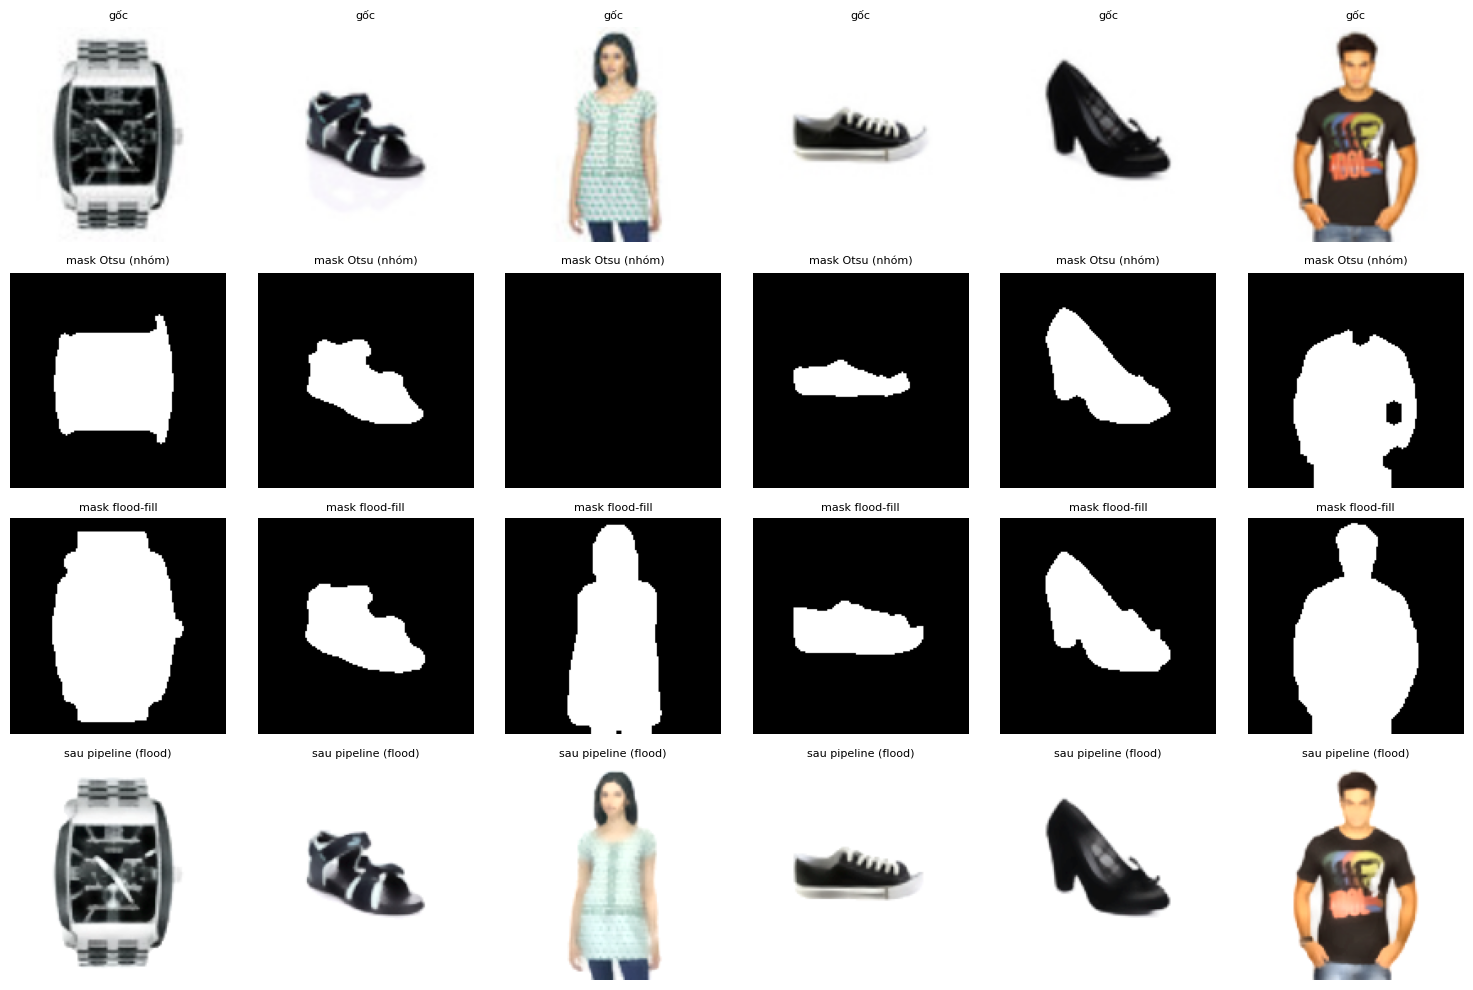

In [6]:
def denoise_image(img): return cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

def remove_background(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k, iterations=1)
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k, iterations=2)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    mask = np.zeros_like(binary)
    if n > 1: mask[labels == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])] = 255
    ratio = (mask > 0).mean()
    if ratio < 0.05 or ratio > 0.95: mask[:] = 255
    return np.where(mask[..., None] > 0, img, 255).astype(np.uint8), mask

def apply_clahe(img):
    l, a, b = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def bg_floodfill(img, thr=235):
    """Nền = vùng gần trắng liền với viền ảnh. Phần trắng nằm trong sản phẩm (giày trắng, áo trắng) được giữ lại."""
    near_white = (img.min(axis=2) >= thr).astype(np.uint8)
    _, lab_, _, _ = cv2.connectedComponentsWithStats(near_white, connectivity=4)
    border = np.unique(np.concatenate([lab_[0], lab_[-1], lab_[:, 0], lab_[:, -1]])); border = border[border != 0]
    bg = np.isin(lab_, border) & (near_white > 0)
    mask = (~bg).astype(np.uint8) * 255
    k = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(cv2.morphologyEx(mask, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)
    ratio = (mask > 0).mean()
    if ratio < 0.05 or ratio > 0.95: mask[:] = 255
    return np.where(mask[..., None] > 0, img, 255).astype(np.uint8), mask

def preprocess_image(img):                       # img đã là IMG×IMG (resize + padding trắng ở bước nạp)
    d = denoise_image(img)
    out, mask = bg_floodfill(d) if BG_METHOD == 'flood' else remove_background(d)
    return apply_clahe(out), mask

fig, ax = plt.subplots(4, 6, figsize=(15, 10))
for j, i in enumerate(rng.choice(len(df), 6, replace=False)):
    _, m_otsu = remove_background(denoise_image(X[i])); _, m_flood = bg_floodfill(denoise_image(X[i])); p, _ = preprocess_image(X[i])
    for r_, (im, t) in enumerate([(X[i], 'gốc'), (m_otsu, 'mask Otsu (nhóm)'), (m_flood, 'mask flood-fill'), (p, f'sau pipeline ({BG_METHOD})')]):
        ax[r_, j].imshow(im if r_ in (1, 2) else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap='gray'); ax[r_, j].axis('off'); ax[r_, j].set_title(t, fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/preprocess_examples.png', dpi=120); plt.show()

In [7]:
def hc_cells(img, mask, g):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV); gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, 8, 1, 'uniform').astype(int)
    H, W = gray.shape; hs, ls = [], []
    for i in range(g):
        for j in range(g):
            ys, ye, xs, xe = i * H // g, (i + 1) * H // g, j * W // g, (j + 1) * W // g
            mm = None if mask is None else np.ascontiguousarray(mask[ys:ye, xs:xe])
            h = cv2.calcHist([np.ascontiguousarray(hsv[ys:ye, xs:xe])], [0, 1, 2], mm, [8, 4, 4], [0, 180, 0, 256, 0, 256]).ravel()
            lv = lbp[ys:ye, xs:xe] if mm is None else lbp[ys:ye, xs:xe][mm > 0]
            l = np.bincount(lv.ravel(), minlength=10)[:10].astype(np.float32)
            hs.append(np.sqrt(h / (h.sum() + 1e-9))); ls.append(np.sqrt(l / (l.sum() + 1e-9)))
    return np.concatenate(hs).astype(np.float32), np.concatenate(ls).astype(np.float32)

def hc_pipeline(img, g):                          # toàn bộ pipeline cho 1 ảnh bất kỳ (dùng cho query/ảnh nhiễu)
    p, m = preprocess_image(img); return hc_cells(p, m, g)

def hc_from_imgs(imgs, name):
    """Đặc trưng handcrafted cho ảnh bất kỳ theo đúng tên biến thể (vd. 'HC raw 2x2' hoặc 'HC proc+mask 3x3')."""
    g = int(name[-3])
    f = (lambda im: hc_cells(cv2.GaussianBlur(im, (3, 3), 0), None, g)) if name.startswith('HC raw') else (lambda im: hc_pipeline(im, g))
    r = pmap(f, list(imgs), 4)
    return cat_eq(l2n(np.stack([x[0] for x in r])), l2n(np.stack([x[1] for x in r])))

def eval_one(img):
    proc, mask = preprocess_image(img); blur = cv2.GaussianBlur(img, (3, 3), 0)
    out = {'nomask': hc_cells(proc, None, 1)}
    for g in (1, 2, 3): out[('raw', g)] = hc_cells(blur, None, g); out[g] = hc_cells(proc, mask, g)
    return out, proc, bool((mask == 255).all())

t0 = time.time()
r = pmap(eval_one, X[EV], 4, 'tiền xử lý + handcrafted')
XP = np.stack([x[1] for x in r])                 # ảnh đã tiền xử lý (dùng cho ablation deep)
print(f'Tách nền ({BG_METHOD}) thất bại -> fallback mask toàn ảnh: {np.mean([x[2] for x in r]):.1%} ảnh')
def _blk(key): return cat_eq(l2n(np.stack([x[0][key][0] for x in r])), l2n(np.stack([x[0][key][1] for x in r])))
Z = {}
for g in (1, 2, 3): Z[f'HC raw {g}x{g}'] = _blk(('raw', g))
Z['HC proc, không mask'] = _blk('nomask')
for g in (1, 2, 3): Z[f'HC proc+mask {g}x{g}'] = _blk(g)
HC_NAMES = list(Z); HC_CAND = [n for n in HC_NAMES if n[-3:] in ('1x1', '2x2', '3x3')]; del r
print('Handcrafted xong %.0fs' % (time.time() - t0), {k: v.shape for k, v in Z.items()})

tiền xử lý + handcrafted:   0%|          | 0/22936 [00:00<?, ?it/s]

Tách nền (flood) thất bại -> fallback mask toàn ảnh: 1.6% ảnh
Handcrafted xong 325s {'HC raw 1x1': (22936, 138), 'HC raw 2x2': (22936, 552), 'HC raw 3x3': (22936, 1242), 'HC proc, không mask': (22936, 138), 'HC proc+mask 1x1': (22936, 138), 'HC proc+mask 2x2': (22936, 552), 'HC proc+mask 3x3': (22936, 1242)}


# 4. Deep: ResNet50 pretrained

In [8]:
import torch, torch.nn as nn, torch.nn.functional as TF, torchvision      
dev = 'cuda' if torch.cuda.is_available() else 'cpu'                       
MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)    
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)     
print('device:', dev)                                                       

def to_tensor(batch_bgr):
    x = torch.from_numpy(np.ascontiguousarray(batch_bgr[..., ::-1])).to(dev).permute(0, 3, 1, 2).float() / 255
    return (x - MEAN) / STD

def gem(x, p=3.0): return x.float().clamp(min=1e-6).pow(p).mean((2, 3)).pow(1.0 / p)   # tính fp32 tránh tràn số khi autocast

@torch.no_grad()
def run_batches(fn, imgs, bs=256):
    """fn(x) -> tensor hoặc list tensor. Trả về list mảng numpy (nối theo batch)."""
    outs = None
    for s in range(0, len(imgs), bs):
        with torch.autocast(device_type='cuda', enabled=(dev == 'cuda')):
            o = fn(to_tensor(imgs[s:s + bs]))
        o = [t.float().cpu().numpy() for t in (o if isinstance(o, (list, tuple)) else [o])]
        outs = [[a] for a in o] if outs is None else [prev + [a] for prev, a in zip(outs, o)]
    return [np.concatenate(v) for v in outs]

base = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2).to(dev).eval()

def multi_forward(x):
    x = base.maxpool(base.relu(base.bn1(base.conv1(x))))
    l2 = base.layer2(base.layer1(x)); l3 = base.layer3(l2); l4 = base.layer4(l3)
    return [l2.mean((2, 3)), l3.mean((2, 3)), l4.mean((2, 3)), gem(l4)]

PRE_NAMES = ['ResNet50 pretrained layer2-GAP', 'ResNet50 pretrained layer3-GAP', 'ResNet50 pretrained layer4-GAP', 'ResNet50 pretrained layer4-GeM']
t0 = time.time()
for n, e in zip(PRE_NAMES, run_batches(multi_forward, X[EV])): Z[n] = l2n(e)
EXTRA_PRE = ['ResNet50 pretrained layer4-GAP (ảnh tiền xử lý)', 'VGG16 pretrained fc7']
Z[EXTRA_PRE[0]] = l2n(run_batches(lambda x: multi_forward(x)[2], XP)[0])
vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.IMAGENET1K_V1); vgg.classifier = vgg.classifier[:-1]
vgg = vgg.to(dev).eval(); Z[EXTRA_PRE[1]] = l2n(run_batches(vgg, X[EV])[0]); del vgg
print('Pretrained embeddings xong %.0fs' % (time.time() - t0))

device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 240MB/s]


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 193MB/s] 


Pretrained embeddings xong 46s


# 4b. Ablation tiền xử lý từng bước (RQ0)
Mỗi biến thể được áp lên **query test + gallery con 6000 ảnh**, rồi đo mAP của Hist+LBP (1×1) và ResNet50-L4 pretrained.

In [9]:
def _ck(f): return lambda im: (lambda o, m: (apply_clahe(o), m))(*f(denoise_image(im)))
VARIANTS = {
    'raw (không xử lý)':                 lambda im: (im, None),
    'chỉ khử nhiễu':                     lambda im: (denoise_image(im), None),
    'tách nền Otsu (nhóm)':              lambda im: remove_background(im),
    'tách nền flood-fill':               lambda im: bg_floodfill(im),
    'khử nhiễu+Otsu+CLAHE (pipeline cũ)': _ck(remove_background),
    'khử nhiễu+flood':                   lambda im: bg_floodfill(denoise_image(im)),
    'khử nhiễu+flood+CLAHE':             _ck(bg_floodfill),
}
sub_g = np.random.RandomState(1).choice(gal_idx, min(6000, len(gal_idx)), replace=False)
sub_ids = np.concatenate([test_idx, sub_g]); Rsub = atype[test_idx][:, None] == atype[sub_g][None, :]
abl = []
for nm, fn in VARIANTS.items():
    def one(im, fn=fn):
        o, m = fn(im); h, l = hc_cells(o, m, 1); return o, h, l
    rr = pmap(one, X[sub_ids], 4, nm)
    imgs_v = np.stack([x[0] for x in rr])
    hc_v = cat_eq(l2n(np.stack([x[1] for x in rr])), l2n(np.stack([x[2] for x in rr])))
    dp_v = l2n(run_batches(lambda x: multi_forward(x)[2], imgs_v)[0])
    row = {'biến thể': nm}
    for tag, E in (('Hist+LBP', hc_v), ('ResNet50-L4', dp_v)):
        ev = summ(evaluate(E[:len(test_idx)] @ E[len(test_idx):].T, Rsub)); row[f'{tag} mAP'] = ev['AP']; row[f'{tag} P@10'] = ev['P@10']
    abl.append(row); del imgs_v, rr
abl = pd.DataFrame(abl).set_index('biến thể').round(4); abl.to_csv(f'{OUT}/ablation_preprocess.csv'); print(abl)

raw (không xử lý):   0%|          | 0/7000 [00:00<?, ?it/s]

chỉ khử nhiễu:   0%|          | 0/7000 [00:00<?, ?it/s]

tách nền Otsu (nhóm):   0%|          | 0/7000 [00:00<?, ?it/s]

tách nền flood-fill:   0%|          | 0/7000 [00:00<?, ?it/s]

khử nhiễu+Otsu+CLAHE (pipeline cũ):   0%|          | 0/7000 [00:00<?, ?it/s]

khử nhiễu+flood:   0%|          | 0/7000 [00:00<?, ?it/s]

khử nhiễu+flood+CLAHE:   0%|          | 0/7000 [00:00<?, ?it/s]

                                    Hist+LBP mAP  Hist+LBP P@10  \
biến thể                                                          
raw (không xử lý)                         0.1098         0.2376   
chỉ khử nhiễu                             0.1033         0.2225   
tách nền Otsu (nhóm)                      0.0795         0.1732   
tách nền flood-fill                       0.0891         0.1989   
khử nhiễu+Otsu+CLAHE (pipeline cũ)        0.0768         0.1639   
khử nhiễu+flood                           0.0864         0.1885   
khử nhiễu+flood+CLAHE                     0.0835         0.1911   

                                    ResNet50-L4 mAP  ResNet50-L4 P@10  
biến thể                                                               
raw (không xử lý)                            0.4408            0.6386  
chỉ khử nhiễu                                0.4074            0.6172  
tách nền Otsu (nhóm)                         0.3245            0.5533  
tách nền flood-fill                 

# 5. Fine-tune ResNet50 bằng batch-hard triplet
* Embedding: layer4-GAP (2048) → Linear(256) → L2-normalize.
* Loss: **batch-hard triplet**, margin 0.3. Batch **PK-sampling**: 16 lớp × 8 ảnh.
* Augmentation (trên GPU): lật ngang + crop/zoom ngẫu nhiên 75–100% + (`AUG_ROBUST`) nhiễu Gauss σ≤20 và làm mờ nhẹ. **Không đổi màu** vì màu là một phần của "giống nhau".
* AdamW (backbone 1e-4, head 1e-3), OneCycle, AMP. Chọn checkpoint theo **mAP val** (gallery con 8000 ảnh).
* Chỉ train trên ảnh **train** của các lớp **seen**.

it 500/1500 loss 0.257 | val mAP 0.5877 | 98s
it 1000/1500 loss 0.102 | val mAP 0.6580 | 195s
it 1500/1500 loss 0.107 | val mAP 0.6674 | 292s


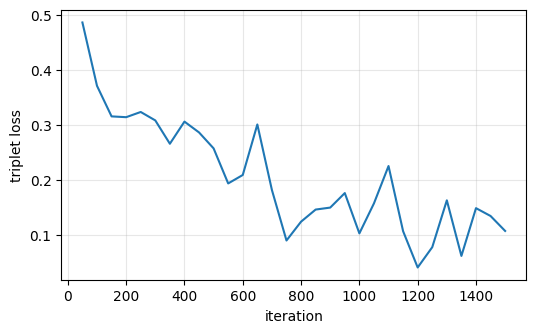

Best val mAP (gallery con): 0.6674


In [10]:
class EmbNet(nn.Module):                                                    
    def __init__(self, dim=EMB):
        super().__init__()
        r = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
        self.body = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        self.fc = nn.Linear(2048, dim)
    def forward(self, x):
        return TF.normalize(self.fc(self.body(x).mean((2, 3))).float(), dim=1)

def batch_hard_triplet(emb, y, margin=MARGIN):                              
    sim = emb @ emb.t()
    d = torch.sqrt(torch.clamp(2 - 2 * sim, min=1e-12))                      # tránh NaN gradient tại d=0
    same = y[:, None] == y[None, :]
    eye = torch.eye(len(y), dtype=torch.bool, device=emb.device)
    hardest_pos = d.masked_fill(~same | eye, -1.0).max(1).values
    hardest_neg = d.masked_fill(same, 1e9).min(1).values
    return TF.relu(hardest_pos - hardest_neg + margin).mean()

def augment(x):                                                             
    B = x.shape[0]
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    s = torch.empty(B, device=x.device).uniform_(0.75, 1.0)
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = s; theta[:, 1, 1] = s
    theta[:, 0, 2] = (1 - s) * (torch.rand(B, device=x.device) * 2 - 1)
    theta[:, 1, 2] = (1 - s) * (torch.rand(B, device=x.device) * 2 - 1)
    grid = TF.affine_grid(theta, list(x.shape), align_corners=False)
    x = TF.grid_sample(x, grid, padding_mode='border', align_corners=False)
    if AUG_ROBUST:                                                            # tăng độ bền với nhiễu / mờ (RQ4)
        sig = torch.rand(B, 1, 1, 1, device=x.device) * (20 / 255)
        use_noise = (torch.rand(B, 1, 1, 1, device=x.device) < 0.5).float()
        x = x + torch.randn_like(x) * (sig / STD) * use_noise
        blur = TF.avg_pool2d(x, 3, 1, 1, count_include_pad=False)
        x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.3, blur, x)
    return x

by_class = {c: np.where(lab[train_idx] == c)[0] for c in np.unique(lab[train_idx])}
by_class = {c: train_idx[v] for c, v in by_class.items() if len(v) >= 2}
train_classes = np.array(list(by_class)); P_USE = min(P_CLS, len(train_classes))
rng_t = np.random.RandomState(SEED)
def sample_pk():
    cls = rng_t.choice(train_classes, P_USE, replace=False)
    return np.concatenate([rng_t.choice(by_class[c], K_IMG, replace=len(by_class[c]) < K_IMG) for c in cls])

gsub = rng_t.choice(gal_idx, min(8000, len(gal_idx)), replace=False)
R_val_sub = atype[val_idx][:, None] == atype[gsub][None, :]
def val_map(net):
    net.eval()
    q = run_batches(net, X[val_idx])[0]; g = run_batches(net, X[gsub])[0]
    net.train()
    return summ(evaluate(q @ g.T, R_val_sub))['AP']

def train_triplet():
    net = EmbNet().to(dev); net.train()
    opt = torch.optim.AdamW([{'params': net.body.parameters(), 'lr': 1e-4}, {'params': net.fc.parameters(), 'lr': 1e-3}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[1e-4, 1e-3], total_steps=ITERS, pct_start=0.1)
    scaler = torch.cuda.amp.GradScaler(enabled=(dev == 'cuda'))
    best, best_state, hist, t0 = -1, None, [], time.time()
    for it in range(1, ITERS + 1):
        idx = sample_pk()
        x = augment(to_tensor(X[idx])); y = torch.from_numpy(lab[idx]).to(dev)
        with torch.autocast(device_type='cuda', enabled=(dev == 'cuda')):
            e = net(x)
        loss = batch_hard_triplet(e, y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        if it % 50 == 0: hist.append((it, loss.item()))
        if it % EVAL_EVERY == 0 or it == ITERS:
            m = val_map(net)
            print(f'it {it}/{ITERS} loss {loss.item():.3f} | val mAP {m:.4f} | {time.time() - t0:.0f}s')
            if m > best: best, best_state = m, {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state); net.eval()
    return net, hist, best

ft_net, loss_hist, best_val = train_triplet()
torch.save(ft_net.state_dict(), f'{OUT}/ft_resnet50_triplet.pt')
plt.figure(figsize=(6, 3.5)); plt.plot(*zip(*loss_hist)); plt.xlabel('iteration'); plt.ylabel('triplet loss'); plt.grid(alpha=.3)
plt.savefig(f'{OUT}/train_loss.png', dpi=130, bbox_inches='tight'); plt.show()
Z['Fine-tuned ResNet50 (triplet)'] = run_batches(ft_net, X[EV])[0]
print('Best val mAP (gallery con):', round(best_val, 4))

# 6. Đề xuất cuối: Fine-tuned embedding + handcrafted theo vùng (late fusion)
`sim = α·cos(fine-tuned) + (1−α)·cos(handcrafted g×g)`. **g và α chọn trên val.**

Handcrafted tốt nhất trên VAL: HC raw 3x3 {'HC raw 1x1': 0.1078, 'HC raw 2x2': 0.1337, 'HC raw 3x3': 0.1874, 'HC proc+mask 1x1': 0.0843, 'HC proc+mask 2x2': 0.0936, 'HC proc+mask 3x3': 0.1738}
α tối ưu trên VAL – tiêu chí loại: 1.0 | tiêu chí loại+màu: 0.3


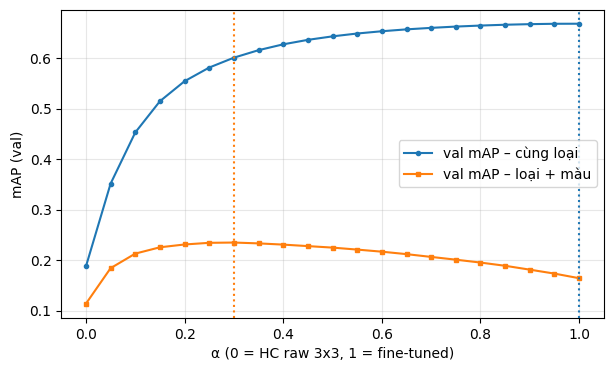

α cho bản pretrained+handcrafted (chọn trên VAL): 0.65


In [11]:
FT = 'Fine-tuned ResNet50 (triplet)'
def S(name, q): return Z[name][pos[q]] @ Z[name][pos[gal_idx]].T
alphas = np.round(np.arange(0, 1.0001, 0.05), 2)
hc_val = {n: summ(evaluate(S(n, val_idx), REL['val']))['AP'] for n in HC_CAND}          # chọn handcrafted theo mAP val của CHÍNH nó
HC_BEST = max(hc_val, key=hc_val.get); print('Handcrafted tốt nhất trên VAL:', HC_BEST, {k: round(v, 4) for k, v in hc_val.items()})
REL['val_strict'] = rel_strict(val_idx)
S_ft_val, S_hc_val = S(FT, val_idx), S(HC_BEST, val_idx)
cur_t = [summ(evaluate(a * S_ft_val + (1 - a) * S_hc_val, REL['val']))['AP'] for a in alphas]
cur_c = [summ(evaluate(a * S_ft_val + (1 - a) * S_hc_val, REL['val_strict']))['AP'] for a in alphas]
ALPHA, ALPHA_C = float(alphas[int(np.argmax(cur_t))]), float(alphas[int(np.argmax(cur_c))])
PROPOSED = f'PROPOSED-type: Fine-tuned + {HC_BEST} (α={ALPHA})'
PROPOSED_C = f'PROPOSED-colour: Fine-tuned + {HC_BEST} (α={ALPHA_C})'
print(f'α tối ưu trên VAL – tiêu chí loại: {ALPHA} | tiêu chí loại+màu: {ALPHA_C}')
plt.figure(figsize=(7, 4))
plt.plot(alphas, cur_t, marker='o', ms=3, label='val mAP – cùng loại'); plt.plot(alphas, cur_c, marker='s', ms=3, label='val mAP – loại + màu')
plt.axvline(ALPHA, color='C0', ls=':'); plt.axvline(ALPHA_C, color='C1', ls=':')
plt.xlabel(f'α (0 = {HC_BEST}, 1 = fine-tuned)'); plt.ylabel('mAP (val)'); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f'{OUT}/alpha_curve.png', dpi=140, bbox_inches='tight'); plt.show()

PRE_L4 = PRE_NAMES[2]                                  # ablation: kết hợp nhưng KHÔNG fine-tune
S_pre_val, S_hcb_val = S(PRE_L4, val_idx), S(HC_BEST, val_idx)
cur = [summ(evaluate(a * S_pre_val + (1 - a) * S_hcb_val, REL['val']))['AP'] for a in alphas]
ALPHA_PRE = float(alphas[int(np.argmax(cur))]); PRE_FUSED = f'Pretrained R50-L4 + {HC_BEST} (α={ALPHA_PRE})'
print('α cho bản pretrained+handcrafted (chọn trên VAL):', ALPHA_PRE)

# 7. Kết quả trên TEST (cùng `articleType`) – tổng, lớp *seen*, lớp *unseen*

                                                    P@1    P@10     mAP     MRR  mAP seen  mAP unseen
Random                                            0.042  0.0446  0.0465  0.1273    0.0551      0.0207
HC raw 1x1                                        0.361  0.2841  0.1046  0.5012    0.1210      0.0555
HC raw 2x2                                        0.526  0.3918  0.1302  0.6376    0.1493      0.0730
HC raw 3x3                                        0.601  0.4804  0.1828  0.7028    0.2085      0.1054
HC proc, không mask                               0.359  0.2773  0.0951  0.4928    0.1084      0.0549
HC proc+mask 1x1                                  0.303  0.2372  0.0819  0.4395    0.0958      0.0400
HC proc+mask 2x2                                  0.430  0.3100  0.0943  0.5349    0.1102      0.0468
HC proc+mask 3x3                                  0.550  0.4283  0.1637  0.6583    0.1884      0.0897
ResNet50 pretrained layer2-GAP                    0.774  0.6695  0.2849  0.8393   

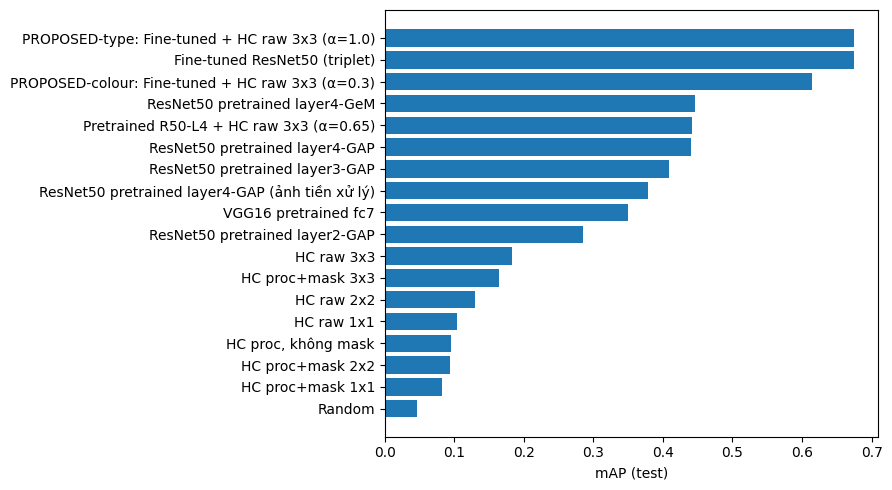

In [12]:
rs = np.random.RandomState(SEED)
names = HC_NAMES + PRE_NAMES + EXTRA_PRE + [FT]
PQ = {'Random': evaluate(rs.rand(len(test_idx), len(gal_idx)), REL['test'])}
for n in names: PQ[n] = evaluate(S(n, test_idx), REL['test'])
S_prop_t = ALPHA * S(FT, test_idx) + (1 - ALPHA) * S(HC_BEST, test_idx)
PQ[PRE_FUSED] = evaluate(ALPHA_PRE * S(PRE_L4, test_idx) + (1 - ALPHA_PRE) * S(HC_BEST, test_idx), REL['test'])
PQ[PROPOSED] = evaluate(S_prop_t, REL['test'])
S_prop_c = ALPHA_C * S(FT, test_idx) + (1 - ALPHA_C) * S(HC_BEST, test_idx)
PQ[PROPOSED_C] = evaluate(S_prop_c, REL['test'])

qun = is_unseen[test_idx]
rows = {}
for k, v in PQ.items():
    a = summ(v)
    rows[k] = {'P@1': a['P@1'], 'P@10': a['P@10'], 'mAP': a['AP'], 'MRR': a['RR'],
               'mAP seen': summ(v, ~qun)['AP'], 'mAP unseen': summ(v, qun)['AP'] if qun.any() else np.nan}
table = pd.DataFrame(rows).T.round(4); table.to_csv(f'{OUT}/results_test.csv')
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 60)
print(table)

PQS = {k: evaluate(sm, REL['strict']) for k, sm in
       [(HC_BEST, S(HC_BEST, test_idx)), ('ResNet50 pretrained layer4-GAP', S(PRE_NAMES[2], test_idx)), (FT, S(FT, test_idx)),
        (PROPOSED, S_prop_t), (PROPOSED_C, S_prop_c)]}
print('\nTiêu chí chặt (cùng loại + màu):'); print(pd.DataFrame({k: summ(v) for k, v in PQS.items()}).T[['P@10', 'AP', 'RR']].round(4))

plt.figure(figsize=(9, 5)); o = table['mAP'].sort_values().index
plt.barh([k[:48] for k in o], table.loc[o, 'mAP']); plt.xlabel('mAP (test)'); plt.tight_layout()
plt.savefig(f'{OUT}/map_bar.png', dpi=150); plt.show()

# 8. Kiểm định thống kê: bootstrap 95% CI (resample query)
Một khác biệt nhỏ giữa hai phương pháp có thể chỉ do may mắn. Ta lấy khoảng tin cậy 95% của mAP và của **hiệu mAP theo cặp**.

In [13]:
def boot(a, b=None, n=2000, seed=0):
    r = np.random.RandomState(seed); ok = ~np.isnan(a) & (np.ones_like(a, bool) if b is None else ~np.isnan(b))
    x = a[ok] if b is None else a[ok] - b[ok]
    m = np.array([x[r.randint(0, len(x), len(x))].mean() for _ in range(n)])
    return x.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)
for k in [HC_BEST, PRE_NAMES[2], FT, PROPOSED]:
    m, lo, hi = boot(PQ[k]['AP']); print(f'mAP {k[:55]:55s} {m:.4f}  [{lo:.4f}, {hi:.4f}]')
print()
for a, b in [(FT, PRE_NAMES[2]), (PROPOSED, FT), (PROPOSED, PRE_FUSED), (PRE_NAMES[2], HC_BEST), (HC_BEST, HC_NAMES[0])]:
    m, lo, hi = boot(PQ[a]['AP'], PQ[b]['AP']); sig = 'KHÁC BIỆT CÓ Ý NGHĨA' if lo > 0 or hi < 0 else 'không khác biệt rõ ràng'
    print(f'ΔmAP ({a[:30]} − {b[:30]}): {m:+.4f}  [{lo:+.4f}, {hi:+.4f}]  -> {sig}')
m, lo, hi = boot(PQS[PROPOSED_C]['AP'], PQS[FT]['AP']); print(f'ΔmAP tiêu chí loại+màu (PROPOSED-colour − Fine-tuned): {m:+.4f}  [{lo:+.4f}, {hi:+.4f}]')

mAP HC raw 3x3                                              0.1828  [0.1747, 0.1914]
mAP ResNet50 pretrained layer4-GAP                          0.4397  [0.4235, 0.4568]
mAP Fine-tuned ResNet50 (triplet)                           0.6750  [0.6557, 0.6940]
mAP PROPOSED-type: Fine-tuned + HC raw 3x3 (α=1.0)          0.6750  [0.6557, 0.6940]

ΔmAP (Fine-tuned ResNet50 (triplet) − ResNet50 pretrained layer4-GAP): +0.2353  [+0.2216, +0.2483]  -> KHÁC BIỆT CÓ Ý NGHĨA
ΔmAP (PROPOSED-type: Fine-tuned + HC − Fine-tuned ResNet50 (triplet)): +0.0000  [+0.0000, +0.0000]  -> không khác biệt rõ ràng
ΔmAP (PROPOSED-type: Fine-tuned + HC − Pretrained R50-L4 + HC raw 3x3): +0.2336  [+0.2203, +0.2465]  -> KHÁC BIỆT CÓ Ý NGHĨA
ΔmAP (ResNet50 pretrained layer4-GAP − HC raw 3x3): +0.2570  [+0.2425, +0.2721]  -> KHÁC BIỆT CÓ Ý NGHĨA
ΔmAP (HC raw 3x3 − HC raw 1x1): +0.0782  [+0.0739, +0.0825]  -> KHÁC BIỆT CÓ Ý NGHĨA
ΔmAP tiêu chí loại+màu (PROPOSED-colour − Fine-tuned): +0.0655  [+0.0590, +0.0722]


# 9. Phân tích theo lớp và failure cases

Lớp fine-tune cải thiện NHIỀU nhất:
                        gain   n  unseen
cls                                     
Flip Flops             0.488  13   False
Perfume and Body Mist  0.522  16   False
Briefs                 0.601  12   False
Stoles                 0.622   4   False
Night suits            0.627   3   False
Earrings               0.637   8   False
Necklace and Chains    0.656   5   False
Ring                   0.717   3   False

Lớp fine-tune cải thiện ÍT nhất / tệ đi:
                 gain   n  unseen
cls                              
Cufflinks      -0.018   6    True
Tunics          0.017   4   False
Kurtis          0.020   8   False
Ties            0.043   5   False
Capris          0.044  23    True
Sports Sandals  0.055   3   False
Sandals         0.055  73    True
Sweaters        0.056  21    True

Trung bình ΔAP trên lớp seen: +0.2966 | lớp unseen: +0.1147

Cặp nhầm top-1 phổ biến:
(Tops, Tshirts)                 9
(Tshirts, Tops)                 9
(Sports Shoes, Ca

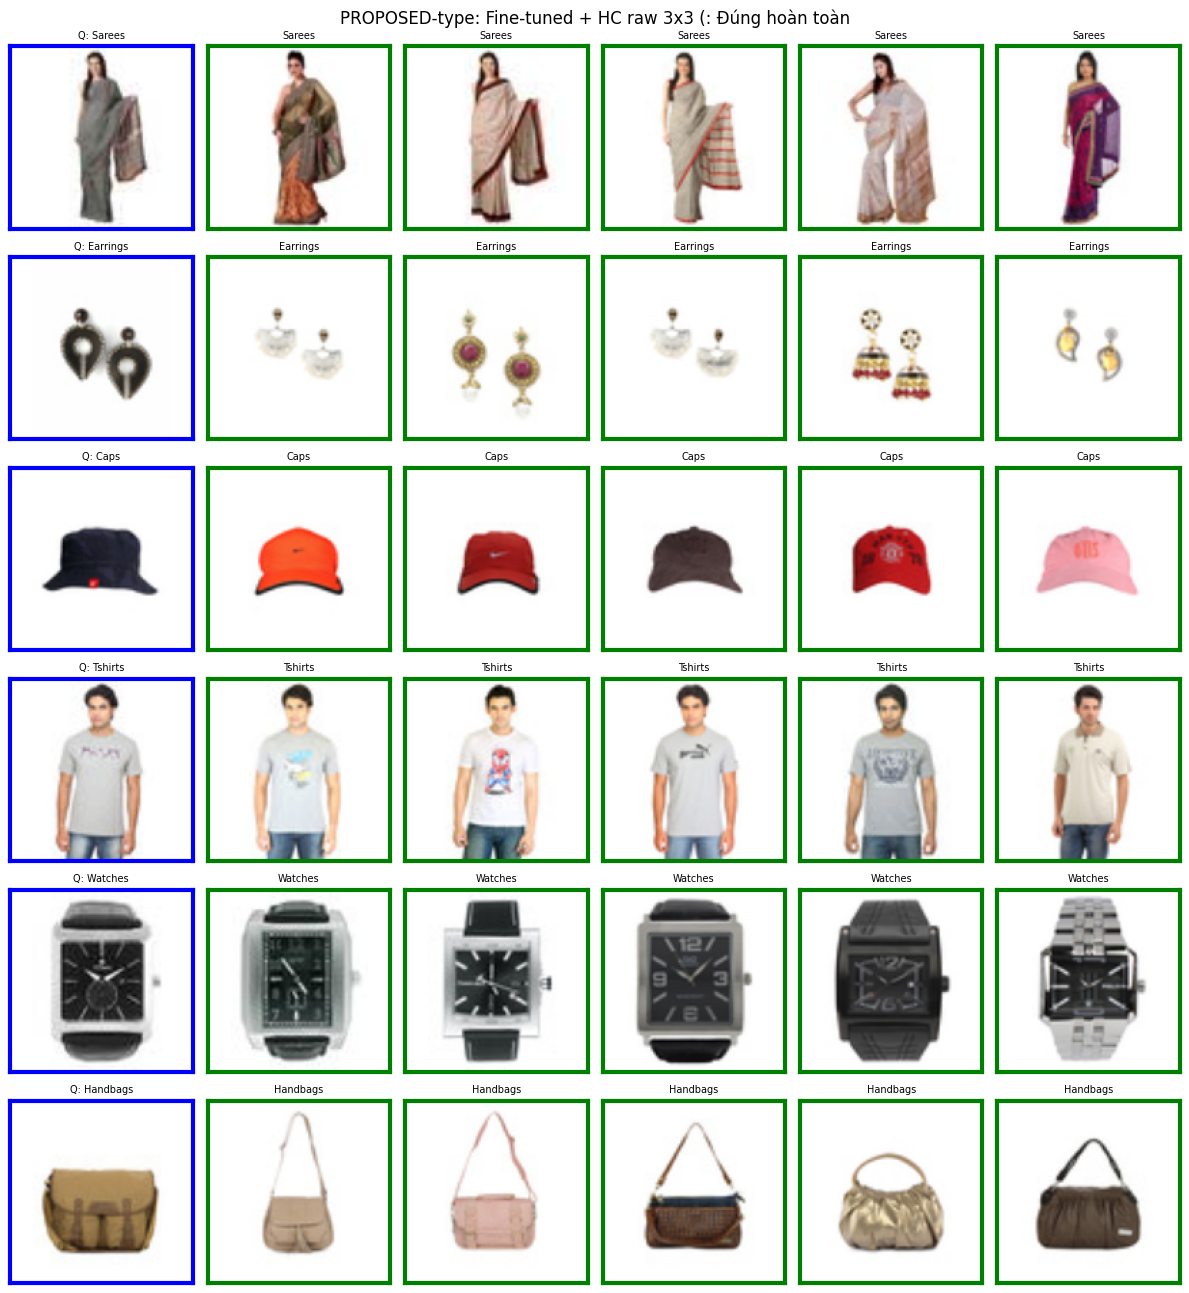

partial 344


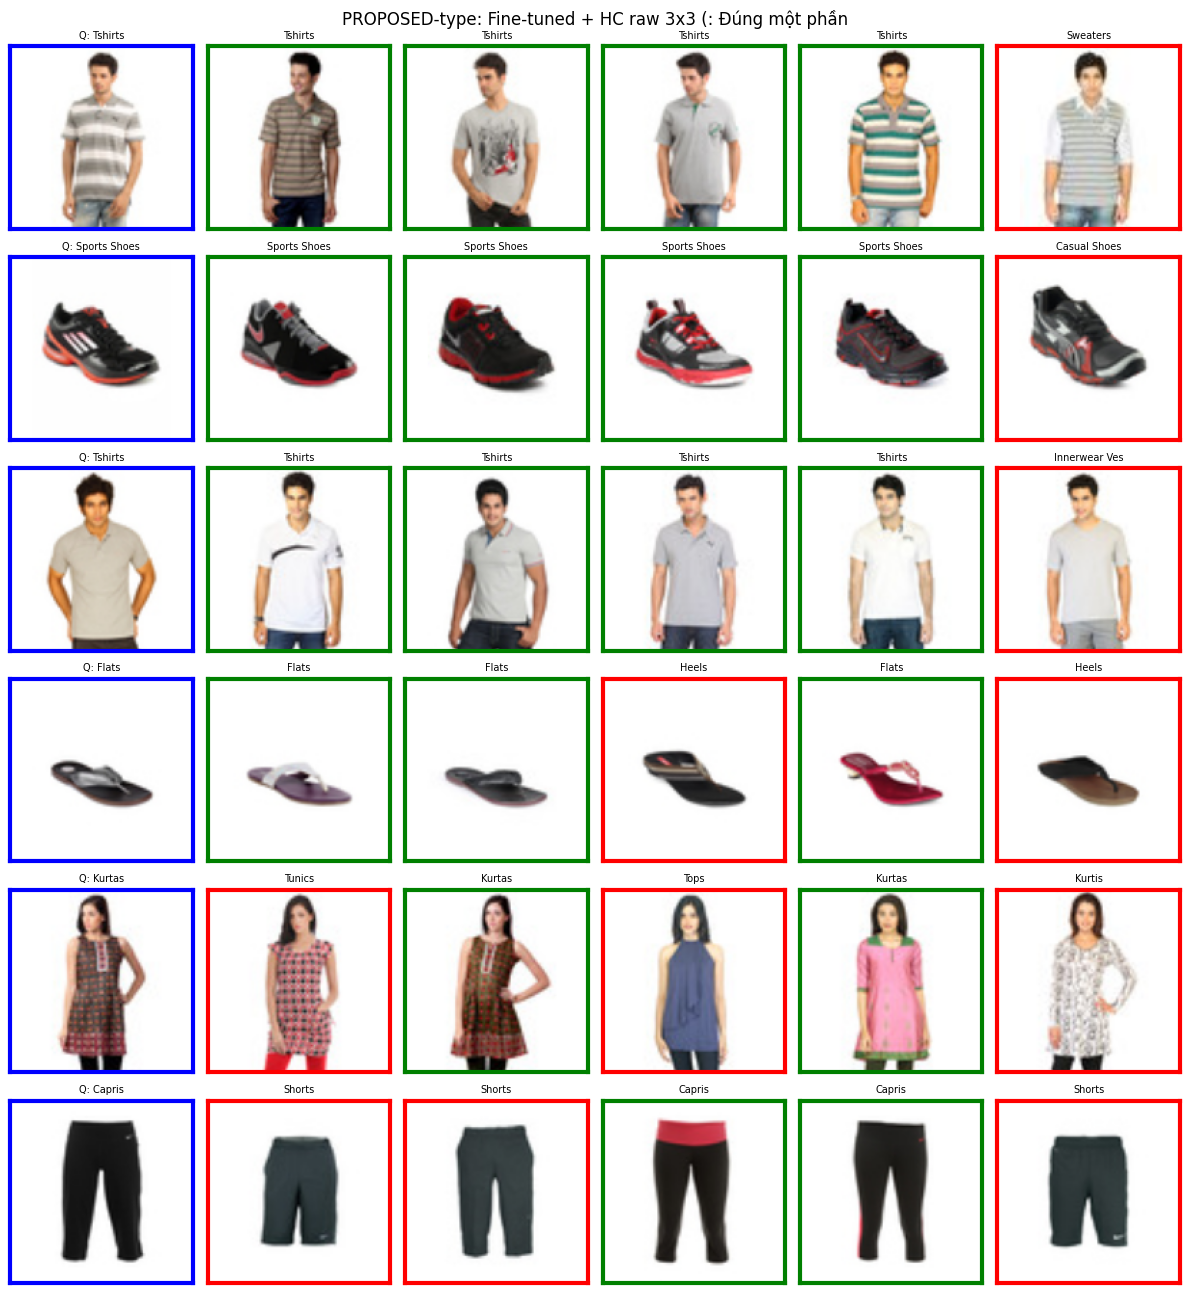

fail 66


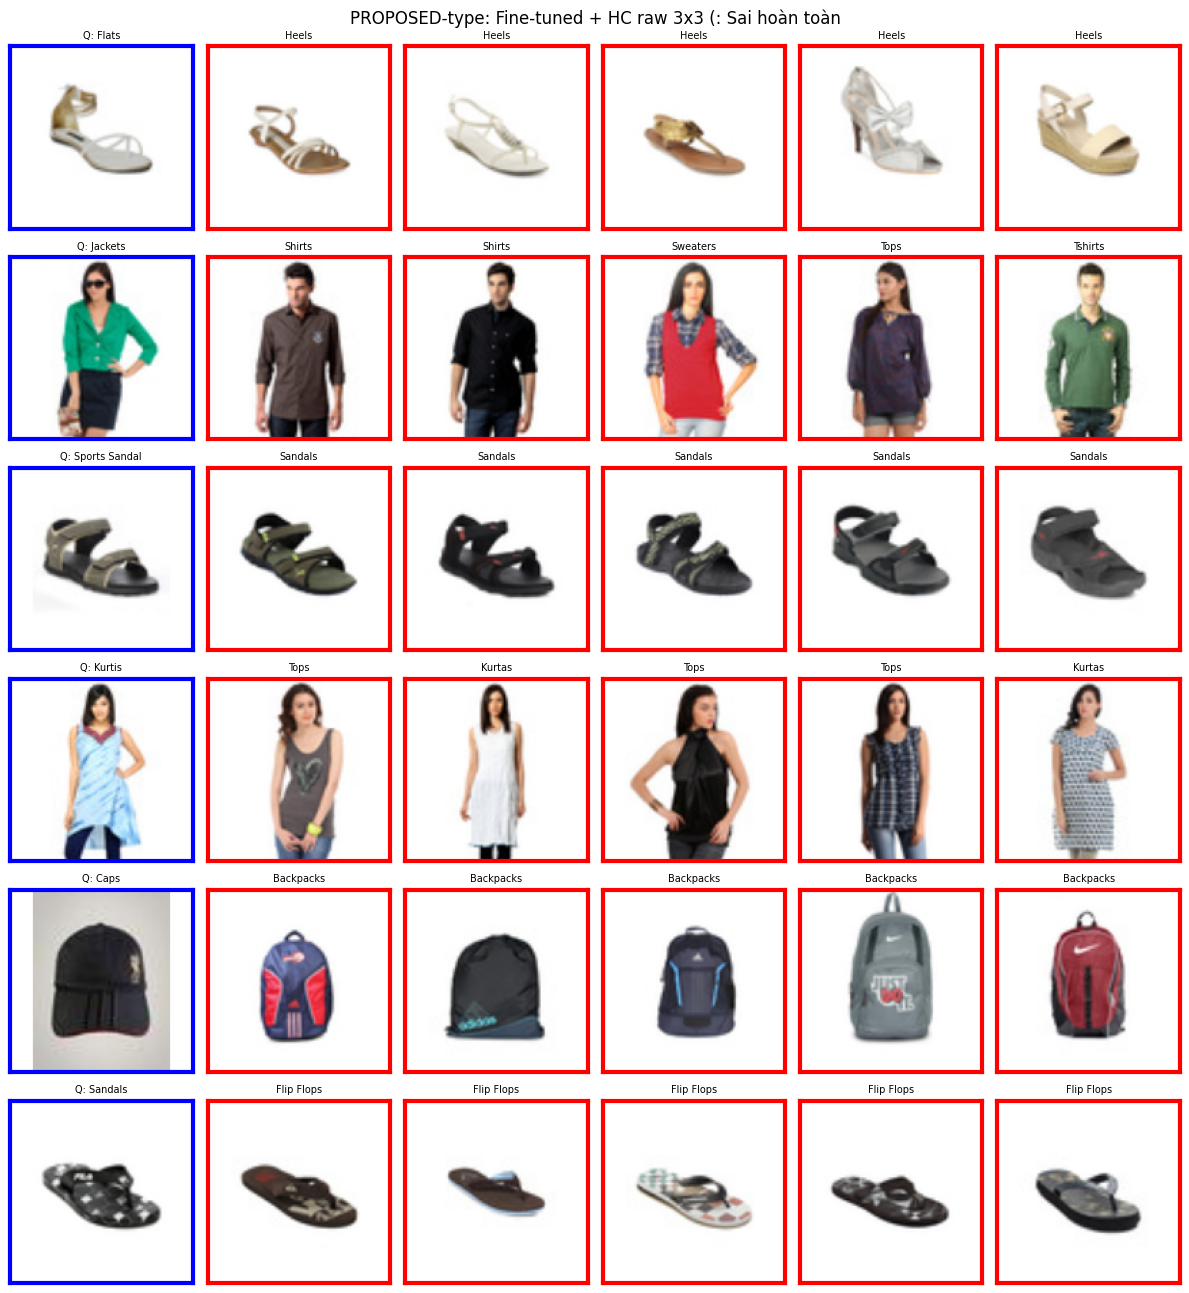

In [14]:
ap_ft, ap_pre = PQ[FT]['AP'], PQ[PRE_NAMES[2]]['AP']
g = pd.DataFrame({'cls': atype[test_idx], 'gain': ap_ft - ap_pre, 'unseen': qun}).groupby('cls').agg(gain=('gain', 'mean'), n=('gain', 'size'), unseen=('unseen', 'max'))
g = g[g['n'] >= 3].dropna().sort_values('gain')
print('Lớp fine-tune cải thiện NHIỀU nhất:'); print(g.tail(8).round(3)); print('\nLớp fine-tune cải thiện ÍT nhất / tệ đi:'); print(g.head(8).round(3))
print(f"\nTrung bình ΔAP trên lớp seen: {g[~g.unseen]['gain'].mean():+.4f} | lớp unseen: {g[g.unseen]['gain'].mean() if g.unseen.any() else float('nan'):+.4f}")

r = PQ[PROPOSED]
wrong = [(atype[test_idx[i]], atype[gal_idx[r['top'][i, 0]]]) for i in range(len(test_idx)) if atype[test_idx[i]] != atype[gal_idx[r['top'][i, 0]]]]
print('\nCặp nhầm top-1 phổ biến:'); print(pd.Series(wrong).value_counts().head(10))

def show_grid(qpos, title, fname, k=5):
    fig, axes = plt.subplots(len(qpos), k + 1, figsize=(2 * (k + 1), 2.2 * len(qpos))); axes = np.atleast_2d(axes)
    for row, i in enumerate(qpos):
        q = test_idx[i]
        for c, (idx, ok) in enumerate([(q, None)] + [(gal_idx[j], atype[gal_idx[j]] == atype[q]) for j in r['top'][i, :k]]):
            ax = axes[row, c]; ax.imshow(cv2.cvtColor(X[idx], cv2.COLOR_BGR2RGB)); ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values(): s.set_edgecolor('blue' if ok is None else ('green' if ok else 'red')); s.set_linewidth(3)
            ax.set_title(('Q: ' if ok is None else '') + atype[idx][:13], fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(f'{OUT}/{fname}', dpi=110); plt.show()
p5 = r['P@5']
for key, arr, t in [('good', np.where(p5 == 1)[0], 'Đúng hoàn toàn'), ('partial', np.where((p5 > 0) & (p5 < 1))[0], 'Đúng một phần'), ('fail', np.where(p5 == 0)[0], 'Sai hoàn toàn')]:
    print(key, len(arr))
    if len(arr): show_grid(rng.choice(arr, min(6, len(arr)), replace=False), f'{PROPOSED[:40]}: {t}', f'{key}.png')

# 10. Độ bền với nhiễu / mờ / sáng / xoay
Chỉ **query test** bị làm hỏng; gallery giữ nguyên. Vẽ mAP theo mức độ cho 3 họ phương pháp.

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

... (6 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

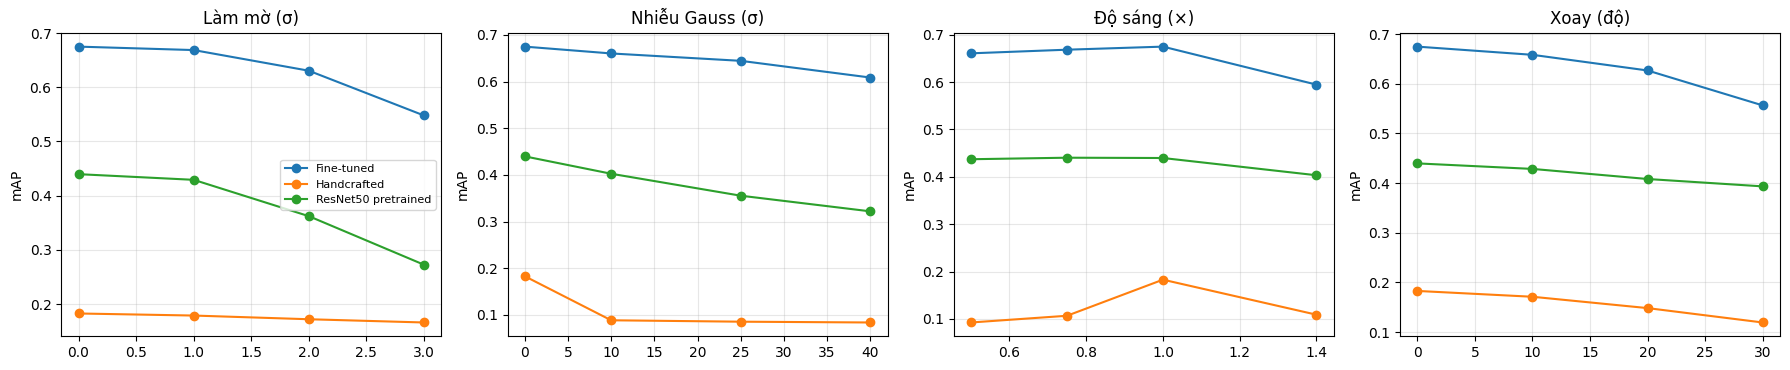

In [15]:
def p_blur(im, s):   return im if s == 0 else cv2.GaussianBlur(im, (0, 0), s)
def p_noise(im, s):  return np.clip(im.astype(np.float32) + np.random.RandomState(0).randn(*im.shape) * s, 0, 255).astype(np.uint8)
def p_bright(im, f): return np.clip(im.astype(np.float32) * f, 0, 255).astype(np.uint8)
def p_rot(im, a):
    M = cv2.getRotationMatrix2D((im.shape[1] / 2, im.shape[0] / 2), a, 1.0)
    return cv2.warpAffine(im, M, (im.shape[1], im.shape[0]), borderValue=(255, 255, 255))
PERT = {'Làm mờ (σ)': (p_blur, [0, 1, 2, 3]), 'Nhiễu Gauss (σ)': (p_noise, [0, 10, 25, 40]),
        'Độ sáng (×)': (p_bright, [0.5, 0.75, 1.0, 1.4]), 'Xoay (độ)': (p_rot, [0, 10, 20, 30])}

def embed_q(method, imgs):
    if method == 'Handcrafted': return hc_from_imgs(imgs, HC_BEST)
    if method == 'ResNet50 pretrained': return l2n(run_batches(multi_forward, imgs)[2])
    return run_batches(ft_net, imgs)[0]
GAL = {'Handcrafted': Z[HC_BEST][pos[gal_idx]], 'ResNet50 pretrained': Z[PRE_NAMES[2]][pos[gal_idx]], 'Fine-tuned': Z[FT][pos[gal_idx]]}
Xq = X[test_idx]; rob = []
for fam, (fn, levels) in PERT.items():
    for lv in levels:
        imgs = np.stack([fn(im, lv) for im in Xq])
        for m in GAL:
            rob.append((fam, lv, m, summ(evaluate(embed_q(m, imgs) @ GAL[m].T, REL['test']))['AP']))
rob = pd.DataFrame(rob, columns=['family', 'level', 'method', 'mAP'])
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, (fam, d) in zip(ax, rob.groupby('family', sort=False)):
    for m, dd in d.groupby('method'): a.plot(dd['level'], dd['mAP'], marker='o', label=m)
    a.set_title(fam); a.set_ylabel('mAP'); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{OUT}/robustness.png', dpi=140); plt.show()
rob.to_csv(f'{OUT}/robustness.csv', index=False)

# 11. Trực quan hóa không gian embedding (t-SNE)
Dấu **x** = lớp unseen (mô hình chưa từng thấy khi fine-tune). Nếu fine-tune tổng quát tốt, các lớp unseen vẫn tạo cụm.

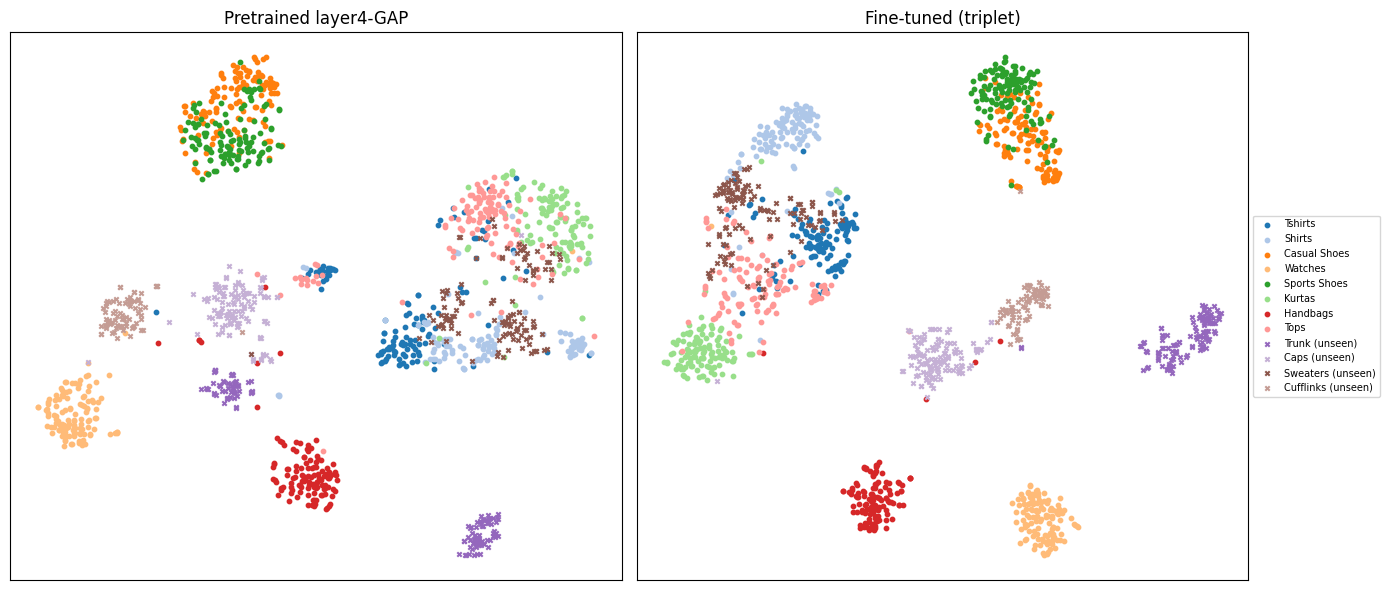

In [16]:
from sklearn.manifold import TSNE
top_cls = list(pd.Series(atype[gal_idx]).value_counts().index)
show = [c for c in top_cls if c not in unseen][:8] + [c for c in unseen][:4]
sel = np.concatenate([rng.choice(gal_idx[atype[gal_idx] == c], min(120, (atype[gal_idx] == c).sum()), replace=False) for c in show])
fig, ax = plt.subplots(1, 2, figsize=(14, 6)); cmap = plt.get_cmap('tab20')
for a, name, t in zip(ax, [PRE_NAMES[2], FT], ['Pretrained layer4-GAP', 'Fine-tuned (triplet)']):
    emb = TSNE(n_components=2, perplexity=30, init='pca', random_state=0).fit_transform(Z[name][pos[sel]])
    for i, c in enumerate(show):
        m = atype[sel] == c
        a.scatter(emb[m, 0], emb[m, 1], s=10, color=cmap(i), marker='x' if c in unseen else 'o', label=c + (' (unseen)' if c in unseen else ''))
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
ax[1].legend(fontsize=7, loc='center left', bbox_to_anchor=(1, 0.5)); plt.tight_layout(); plt.savefig(f'{OUT}/tsne.png', dpi=140, bbox_inches='tight'); plt.show()

# 12. Tốc độ – bộ nhớ – độ chính xác với FAISS (RQ5)
So sánh tìm kiếm chính xác (numpy, FAISS Flat) với xấp xỉ (IVF với nhiều `nprobe`, Product Quantization) trên embedding đã fine-tune (256-d).

In [17]:
try:
    import faiss
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faiss-cpu'], check=False)
    try: import faiss
    except ImportError: faiss = None

Gq = np.ascontiguousarray(Z[FT][pos[gal_idx]], dtype=np.float32); Qq = np.ascontiguousarray(Z[FT][pos[test_idx]], dtype=np.float32)
d_, n_ = Gq.shape[1], len(Gq)
def p10(I): return float(np.mean(np.take_along_axis(REL['test'], I, axis=1)[:, :10]))
t = time.time(); Se = Qq @ Gq.T; Ie = np.argsort(-Se, axis=1)[:, :10]; t_np = (time.time() - t) * 1000
rows = [('numpy matmul + sort (chính xác)', t_np, p10(Ie), 1.0, n_ * d_ * 4 / 1e6)]
if faiss is not None:
    def bench(name, idx, mem, nprobe=None):
        if nprobe: idx.nprobe = nprobe
        t = time.time(); _, I = idx.search(Qq, 10); ms = (time.time() - t) * 1000
        ov = np.mean([len(set(I[i]) & set(Ie[i])) / 10 for i in range(len(I))]); rows.append((name, ms, p10(I), ov, mem))
    fl = faiss.IndexFlatIP(d_); fl.add(Gq); bench('FAISS Flat (chính xác)', fl, n_ * d_ * 4 / 1e6)
    nl = int(min(256, max(4, n_ // 40)))
    q = faiss.IndexFlatIP(d_); ivf = faiss.IndexIVFFlat(q, d_, nl, faiss.METRIC_INNER_PRODUCT); ivf.train(Gq); ivf.add(Gq)
    for npb in (1, 4, 16): bench(f'FAISS IVF (nlist={nl}, nprobe={npb})', ivf, n_ * d_ * 4 / 1e6, npb)
    pq = faiss.IndexPQ(d_, 16, 8, faiss.METRIC_INNER_PRODUCT); pq.train(Gq); pq.add(Gq); bench('FAISS PQ (m=16, 8 bit)', pq, n_ * 16 / 1e6)
else:
    print('Không cài được faiss – chỉ có kết quả numpy.')
ann = pd.DataFrame(rows, columns=['Phương pháp', 'Thời gian 1000 query (ms)', 'P@10', 'Trùng Top-10 với chính xác', 'Bộ nhớ gallery (MB)']).round(3)
ann.to_csv(f'{OUT}/ann_benchmark.csv', index=False); print(ann.to_string(index=False))

                     Phương pháp  Thời gian 1000 query (ms)  P@10  Trùng Top-10 với chính xác  Bộ nhớ gallery (MB)
 numpy matmul + sort (chính xác)                    596.935 0.777                       1.000               21.612
          FAISS Flat (chính xác)                     68.935 0.777                       1.000               21.612
 FAISS IVF (nlist=256, nprobe=1)                      5.516 0.766                       0.622               21.612
 FAISS IVF (nlist=256, nprobe=4)                     13.537 0.775                       0.942               21.612
FAISS IVF (nlist=256, nprobe=16)                     29.448 0.777                       0.999               21.612
          FAISS PQ (m=16, 8 bit)                    179.139 0.750                       0.193                0.338


# 13. Lưu kết quả cho demo
Lưu embedding của gallery, danh sách đường dẫn và trọng số, để app demo.

In [18]:
np.savez(f'{OUT}/demo_assets.npz', gal_emb_ft=Z[FT][pos[gal_idx]].astype(np.float16), gal_emb_hc=Z[HC_BEST][pos[gal_idx]].astype(np.float16),
         gal_idx=gal_idx, alpha=ALPHA, alpha_colour=ALPHA_C, hc_name=HC_BEST)
df.iloc[gal_idx][['id', 'articleType', 'baseColour', 'path']].to_csv(f'{OUT}/demo_gallery.csv', index=False)
print('Đã lưu: ft_resnet50_triplet.pt, demo_assets.npz, demo_gallery.csv, results_test.csv, ablation_preprocess.csv, robustness.csv, ann_benchmark.csv + các hình .png')

Đã lưu: ft_resnet50_triplet.pt, demo_assets.npz, demo_gallery.csv, results_test.csv, ablation_preprocess.csv, robustness.csv, ann_benchmark.csv + các hình .png


In [19]:
import os, zipfile
from IPython.display import FileLink

W = '/kaggle/working'
print(sorted(f for f in os.listdir(W) if not f.startswith('.')))

keep = ['ft_resnet50_triplet.pt', 'demo_assets.npz', 'demo_gallery.csv', 'results_test.csv',
        'ablation_preprocess.csv', 'robustness.csv', 'ann_benchmark.csv']
keep += [f for f in os.listdir(W) if f.endswith('.png')]

with zipfile.ZipFile(f'{W}/ket_qua_do_an.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in keep:
        if os.path.exists(f'{W}/{f}'): z.write(f'{W}/{f}', f)
        else: print('Thiếu:', f)
print(f"Zip: {os.path.getsize(f'{W}/ket_qua_do_an.zip')/1e6:.0f} MB")
FileLink('ket_qua_do_an.zip')

['ablation_preprocess.csv', 'alpha_curve.png', 'ann_benchmark.csv', 'demo_assets.npz', 'demo_gallery.csv', 'fail.png', 'ft_resnet50_triplet.pt', 'good.png', 'images_128_v2.npz', 'map_bar.png', 'partial.png', 'preprocess_examples.png', 'results_test.csv', 'robustness.csv', 'robustness.png', 'train_loss.png', 'tsne.png']
Zip: 112 MB


/kaggle/working/ket_qua_do_an.zip